# Exchange Rate ? Advanced EDA

Ph?n t?ch chu?i t? gi? ?a bi?n: rolling mean, volatility, rolling correlation v? ki?m ??nh t?nh d?ng ADF/KPSS. D? li?u ??c t? `experiments/datasets/exchange_rate.csv`; kh?ng s?a d? li?u ho?c m? gi?a k?. Ch?y notebook t? b?t k? th? m?c n?o b?n trong repository.

**Quy ??c:** `OT` ???c d?ng l?m chu?i m?c ti?u; volatility l? ?? l?ch chu?n rolling 30 ng?y c?a sai ph?n log (log-return). Rolling correlation minh h?a quan h? gi?a OT v? c?c t? gi? c?n l?i.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss

# T?m repository d?a tr?n c?u tr?c th? m?c, kh?ng ph? thu?c working directory.
def find_repo(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "experiments" / "datasets" / "exchange_rate.csv").exists():
            return p
    raise FileNotFoundError("Kh?ng t?m th?y experiments/datasets/exchange_rate.csv")

REPO = find_repo()
DATA_PATH = REPO / "experiments" / "datasets" / "exchange_rate.csv"
ROLLING_WINDOW = 30
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw = raw.sort_values("date").set_index("date")
num = raw.select_dtypes(include="number")
if "OT" not in num:
    raise ValueError("Dataset c?n c? c?t OT")
print(f"Dataset: {DATA_PATH.relative_to(REPO)} | {len(raw):,} ng?y | {num.shape[1]} chu?i")
display(raw.head())
display(raw.tail())


Dataset: experiments\datasets\exchange_rate.csv | 7,588 ng?y | 8 chu?i


,0,1,2,3,4,5,6,OT
date,,,,,,,,
1990-01-01,0.7855,1.6110,0.861698,0.634196,0.211242,0.006838,0.525486,0.5930
1990-01-02,0.7818,1.6100,0.861104,0.633513,0.211242,0.006863,0.523972,0.5940
1990-01-03,0.7867,1.6293,0.861030,0.648508,0.211242,0.006975,0.526316,0.5973
1990-01-04,0.7860,1.6370,0.862069,0.650618,0.211242,0.006953,0.523834,0.5970
1990-01-05,0.7849,1.6530,0.861995,0.656254,0.211242,0.006940,0.527426,0.5985


,0,1,2,3,4,5,6,OT
date,,,,,,,,
2010-10-06,0.718494,1.222195,0.737485,0.969974,0.143697,0.008500,0.688565,0.690846
2010-10-07,0.721839,1.223459,0.741155,0.977297,0.143763,0.008595,0.690288,0.695701
2010-10-08,0.723197,1.234111,0.745184,0.984446,0.143997,0.008562,0.691419,0.695943
2010-10-09,0.720825,1.233905,0.744131,0.980344,0.143993,0.008555,0.690942,0.692689
2010-10-10,0.720825,1.233905,0.744131,0.980344,0.143993,0.008555,0.690942,0.692689


## Rolling mean v? volatility

Rolling mean 30 ng?y cho m?c OT; volatility 30 ng?y t?nh tr?n log-return ?? ?o ?? bi?n ??ng t??ng ??i. C?c c?a s? ??u ch?a ?? quan s?t ???c ?? tr?ng.


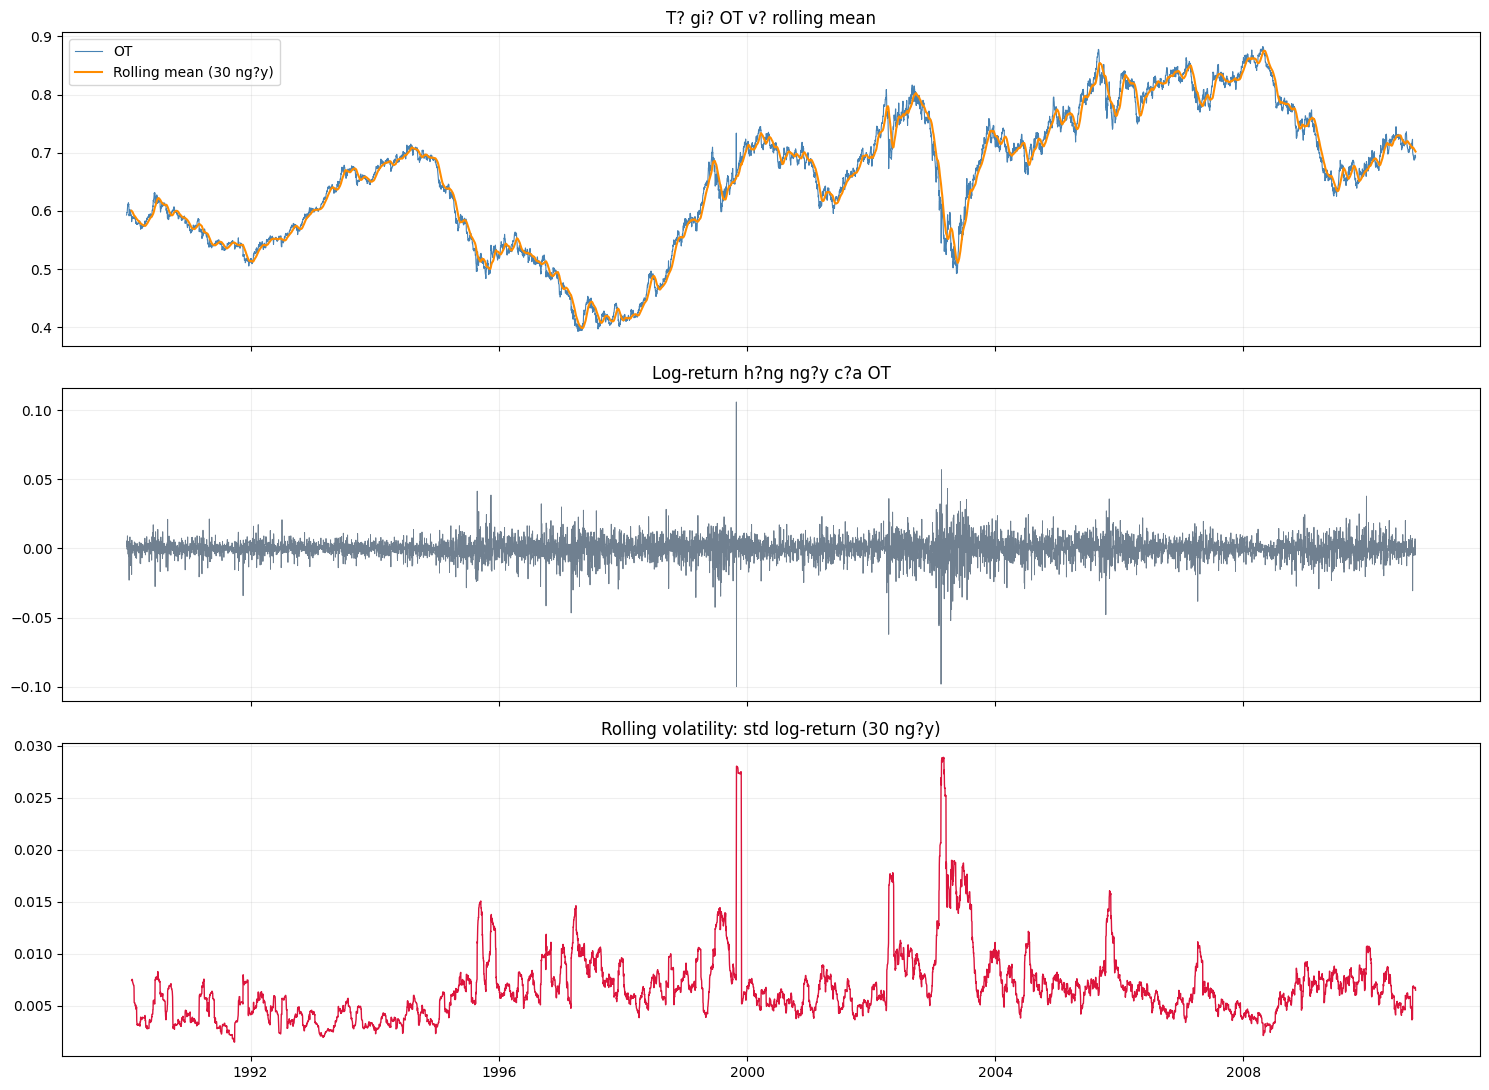

,count,mean,std,min,25%,50%,75%,max
OT,7588.0,0.654418,0.115292,0.393153,0.566000,0.669187,0.734901,0.882379
Rolling_Mean_30d,7559.0,0.654438,0.115031,0.398293,0.566505,0.667769,0.734865,0.875221
Log_Return,7587.0,0.000020,0.007511,-0.099846,-0.003123,0.000000,0.003452,0.105888
Rolling_Volatility_30d,7558.0,0.006729,0.003390,0.001510,0.004672,0.006150,0.007676,0.028894


In [2]:
ot = num["OT"].astype(float)
log_returns = np.log(ot.where(ot > 0)).diff()
rolling_mean = ot.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
rolling_vol = log_returns.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std()

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
axes[0].plot(ot, color="steelblue", lw=0.8, label="OT")
axes[0].plot(rolling_mean, color="darkorange", lw=1.5, label=f"Rolling mean ({ROLLING_WINDOW} ng?y)")
axes[0].set_title("T? gi? OT v? rolling mean"); axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].plot(log_returns, color="slategray", lw=.65)
axes[1].set_title("Log-return h?ng ng?y c?a OT"); axes[1].grid(alpha=.2)
axes[2].plot(rolling_vol, color="crimson", lw=1)
axes[2].set_title(f"Rolling volatility: std log-return ({ROLLING_WINDOW} ng?y)")
axes[2].grid(alpha=.2); plt.tight_layout(); plt.show()

display(pd.DataFrame({"OT":ot, "Rolling_Mean_30d":rolling_mean, "Log_Return":log_returns,
                      "Rolling_Volatility_30d":rolling_vol}).describe().T)


## Rolling correlation

T?nh t??ng quan rolling 90 ng?y gi?a OT v? t?ng chu?i c?n l?i. Ma tr?n t??ng quan to?n m?u ???c hi?n th? th?m ?? ??i chi?u.


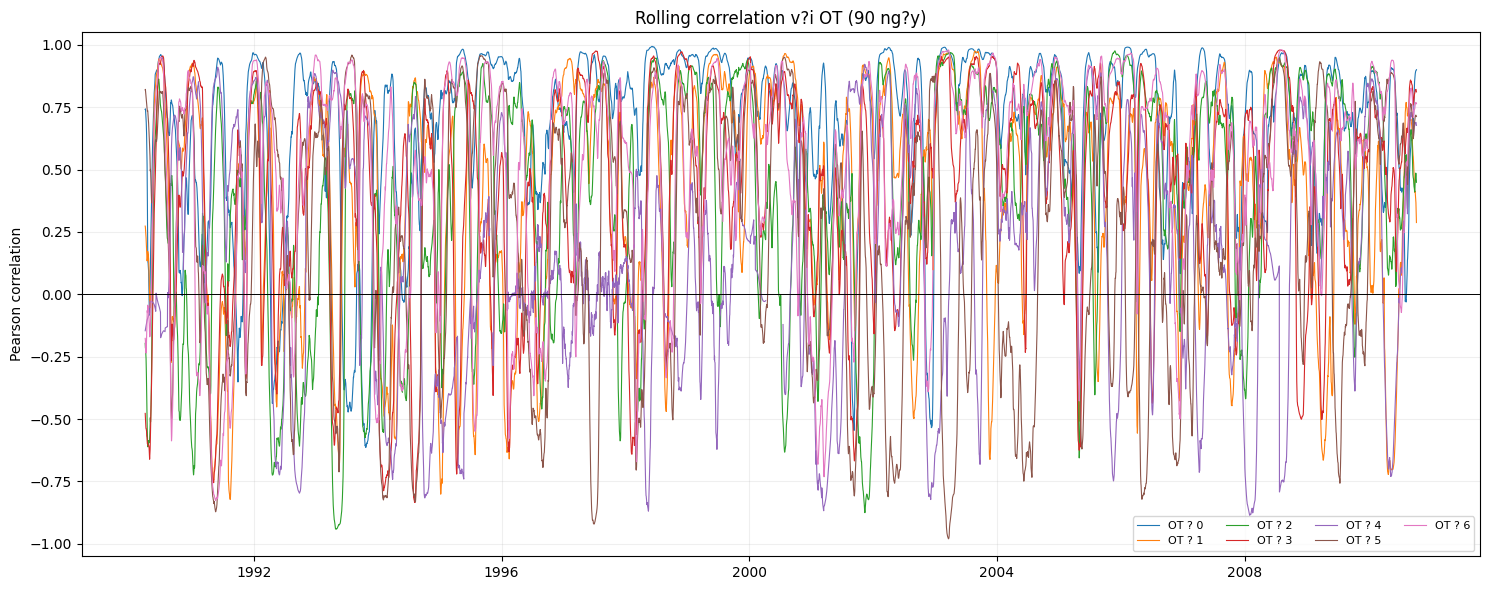

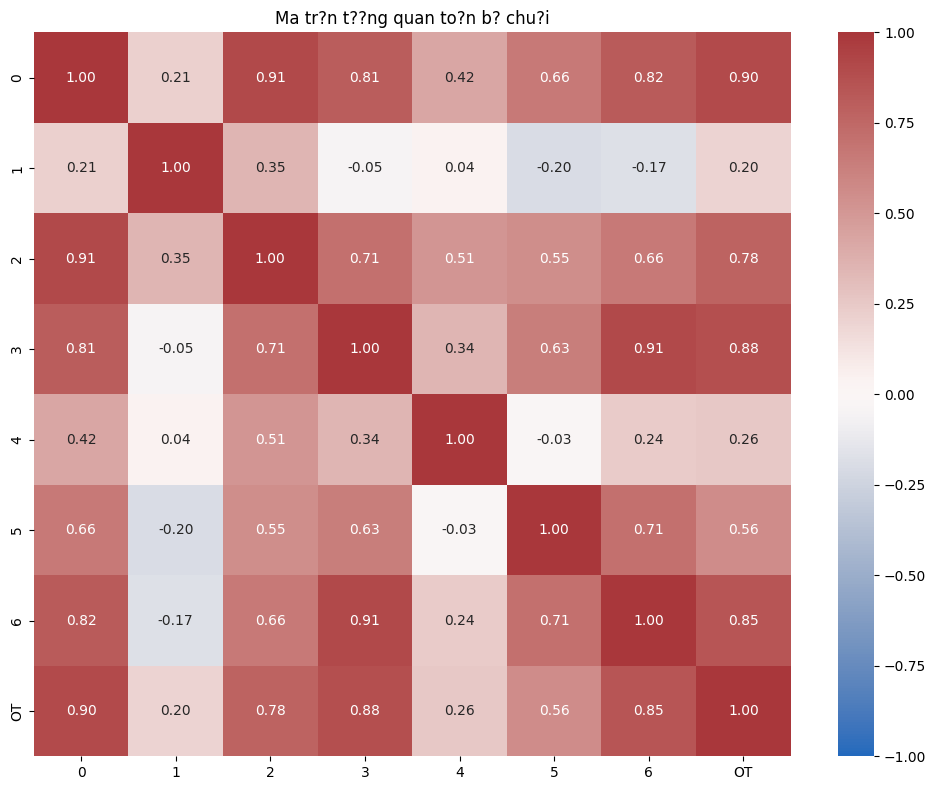

,count,mean,std,min,25%,50%,75%,max
0,7499.0,0.677806,0.328088,-0.613797,0.543313,0.794991,0.917712,0.993815
1,7499.0,0.393011,0.442988,-0.822232,0.085417,0.514597,0.762726,0.974990
2,7499.0,0.389703,0.458426,-0.940815,0.107918,0.478362,0.780342,0.975731
3,7499.0,0.408180,0.430204,-0.834424,0.143805,0.503840,0.758443,0.979393
4,7438.0,NaN,NaN,-inf,-0.148439,0.182107,0.575910,inf
5,7499.0,0.222910,0.513075,-0.980022,-0.181973,0.316704,0.660113,0.959202
6,7499.0,0.508925,0.417332,-0.826665,0.306324,0.660679,0.828227,0.980208


In [3]:
CORR_WINDOW = 90
other_cols = [c for c in num.columns if c != "OT"]
rolling_corr = pd.DataFrame({c: ot.rolling(CORR_WINDOW).corr(num[c].astype(float)) for c in other_cols})
fig, ax = plt.subplots(figsize=(15, 6))
for col in other_cols:
    ax.plot(rolling_corr.index, rolling_corr[col], lw=.8, label=f"OT ? {col}")
ax.axhline(0, color="black", lw=.7); ax.set_ylim(-1.05,1.05)
ax.set_title(f"Rolling correlation v?i OT ({CORR_WINDOW} ng?y)"); ax.set_ylabel("Pearson correlation")
ax.legend(ncol=4, fontsize=8); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Ma tr?n t??ng quan to?n b? chu?i"); plt.tight_layout(); plt.show()
display(rolling_corr.describe().T)


## Ki?m ??nh ADF v? KPSS

ADF c? gi? thuy?t g?c l? chu?i c? unit root (kh?ng d?ng); KPSS c? gi? thuy?t g?c l? chu?i d?ng quanh m?c. B?o c?o k?t qu? ? c? m?c OT v? log-return. K?t lu?n t?ng ki?m ??nh d?ng m?c ? ngh?a 5%; hai ki?m ??nh b? sung cho nhau.


In [4]:
def stationarity_tests(series, series_name):
    x = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    adf = adfuller(x, autolag="AIC")
    kp = kpss(x, regression="c", nlags="auto")
    return [{"Series":series_name,"Test":"ADF","Statistic":adf[0],"p_value":adf[1],
             "Lags":adf[2],"N":adf[3],"Critical_5%":adf[4]["5%"],
             "Conclusion_5%":"D?ng" if adf[1] < .05 else "Kh?ng b?c b? unit root"},
            {"Series":series_name,"Test":"KPSS","Statistic":kp[0],"p_value":kp[1],
             "Lags":kp[2],"N":len(x),"Critical_5%":kp[3]["5%"],
             "Conclusion_5%":"B?c b? gi? thuy?t d?ng" if kp[1] < .05 else "Ch?a b?c b? gi? thuy?t d?ng"}]

results = stationarity_tests(ot, "OT level") + stationarity_tests(log_returns, "OT log-return")
tests = pd.DataFrame(results)
display(tests.style.format({"Statistic":"{:.5f}","p_value":"{:.5g}","Critical_5%":"{:.5f}"}))


C:\Users\domai\AppData\Local\Temp\ipykernel_2456\1919380177.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kp = kpss(x, regression="c", nlags="auto")
C:\Users\domai\AppData\Local\Temp\ipykernel_2456\1919380177.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(x, regression="c", nlags="auto")


,Series,Test,Statistic,p_value,Lags,N,Critical_5%,Conclusion_5%
0,OT level,ADF,-1.72820,0.41665,3,7584,-2.86192,Kh?ng b?c b? unit root
1,OT level,KPSS,7.06611,0.01,54,7588,0.46300,B?c b? gi? thuy?t d?ng
2,OT log-return,ADF,-52.77614,0,2,7584,-2.86192,D?ng
3,OT log-return,KPSS,0.07062,0.1,14,7587,0.46300,Ch?a b?c b? gi? thuy?t d?ng
